# 02 — Exploratory data analysis

**MekongDS: from river forecast to farm action.**

Questions this notebook answers about the 1992–2026 Mekong stage record:

1. What does the annual flood pulse look like, and how does it differ along the river?
2. Which years actually flooded at the Cambodian stations, and how does 2022 compare?
3. How long does a flood wave take to travel downstream (forecast lead we can exploit)?
4. How does the Tonle Sap connection (Prek Kdam) behave relative to the mainstream?
5. Are flood magnitudes trending (Mann-Kendall)?
6. Do wet seasons cluster into distinct regimes?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from mekongds import data
from mekongds.stats_ext import mann_kendall
from mekongds.plotting import set_style, savefig, STAGE_COLORS, PALETTE

set_style()
OUT = data.processed_dir()
FIG = data.figures_dir()

w = pd.read_parquet(OUT / "stage_wide.parquet")
meta = data.load_station_meta().set_index("station")
TH = meta[["floodStage", "alarmStage"]].dropna()

CAM = ["STR", "KRA", "KOM", "NEA", "PPP", "PPB", "KOH", "PRE", "TCH", "CDO"]  # downstream order
MAIN = ["CSA", "CKH", "LUA", "VIE", "NON", "PAK", "NAK", "THA", "SAV", "MUK",
        "PKS", "KHO", "STR", "KRA", "KOM", "NEA", "TCH"]  # mainstem, upstream→downstream

# reliable era for climatology and extremes (from notebook 01)
REL = w.loc["2007-01-01":"2025-12-31"]
REL = REL.loc[~((REL.index >= "2014-06-01") & (REL.index <= "2014-10-31"))]

## 1. The monsoon flood pulse

Day-of-year climatology (reliable era) at four stations spanning the system:
Chiang Saen (upper basin, Thailand), Kratie (Cambodian Mekong), Kompong Cham
(our main forecast point) and Prek Kdam (Tonle Sap outlet).

/var/folders/1b/f39w3b996lx5g88l526sw4sr0000gn/T/ipykernel_13988/1111138910.py:3: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  doy = REL[stn].groupby(REL.index.dayofyear).mean()
/var/folders/1b/f39w3b996lx5g88l526sw4sr0000gn/T/ipykernel_13988/1111138910.py:3: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  doy = REL[stn].groupby(REL.index.dayofyear).mean()
/var/folders/1b/f39w3b996lx5g88l526sw4sr0000gn/T/ipykernel_13988/1111138910.py:3: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  doy = REL[stn].groupby(REL.index.dayofyear).mean()
/var/folders/1b/f39w3b996lx5g88l526sw4sr0000gn/T/ipykernel_13988/1111138910.py:3: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeInde

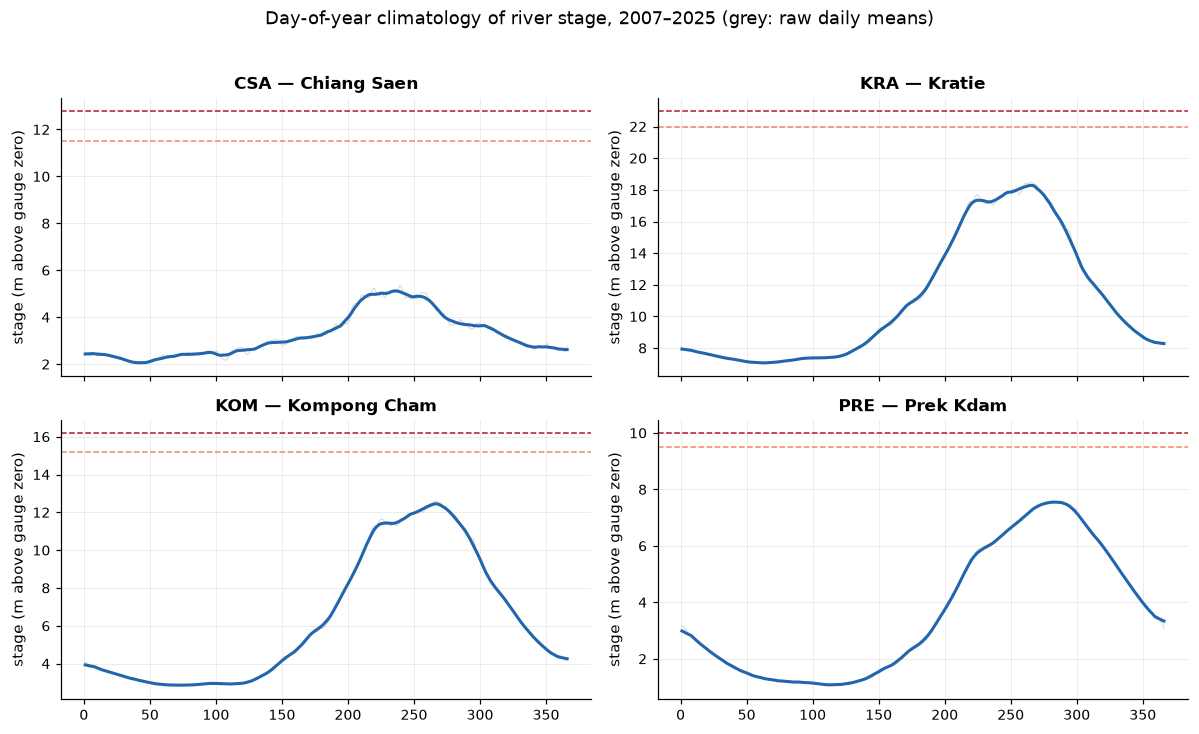

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for ax, stn in zip(axes.ravel(), ["CSA", "KRA", "KOM", "PRE"]):
    doy = REL[stn].groupby(REL.index.dayofyear).mean()
    doy_s = doy.rolling(15, center=True, min_periods=5).mean()
    ax.plot(doy.index, doy, color="lightgrey", lw=0.6)
    ax.plot(doy_s.index, doy_s, color=STAGE_COLORS["normal"], lw=2)
    ax.set_title(f"{stn} — {meta.loc[stn, 'station_name']}")
    ax.set_ylabel("stage (m above gauge zero)")
    if stn in TH.index:
        ax.axhline(TH.loc[stn, "alarmStage"], color=STAGE_COLORS["alarm"], ls="--", lw=1)
        ax.axhline(TH.loc[stn, "floodStage"], color=STAGE_COLORS["flood"], ls="--", lw=1)
fig.suptitle("Day-of-year climatology of river stage, 2007–2025 (grey: raw daily means)", y=1.02)
fig.tight_layout()
savefig(fig, "fig02_seasonal_cycle")
plt.show()

In [3]:
# amplitude of the annual pulse: max minus min of the DOY climatology
amp = {stn: REL[stn].groupby(REL.index.dayofyear).mean().pipe(lambda s: s.max() - s.min())
       for stn in w.columns}
pd.Series(amp).sort_values().round(1).to_frame("annual amplitude (m)").T

/var/folders/1b/f39w3b996lx5g88l526sw4sr0000gn/T/ipykernel_13988/3259541324.py:2: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  amp = {stn: REL[stn].groupby(REL.index.dayofyear).mean().pipe(lambda s: s.max() - s.min())
/var/folders/1b/f39w3b996lx5g88l526sw4sr0000gn/T/ipykernel_13988/3259541324.py:2: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  amp = {stn: REL[stn].groupby(REL.index.dayofyear).mean().pipe(lambda s: s.max() - s.min())
/var/folders/1b/f39w3b996lx5g88l526sw4sr0000gn/T/ipykernel_13988/3259541324.py:2: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  amp = {stn: REL[stn].groupby(REL.index.dayofyear).mean().pipe(lambda s: s.max() - s.min())
/var/folders/1b/f39w3b996lx5g88l526sw4sr0000gn/T/ipykernel_13988/32595413

,CDO,TCH,CSA,NEA,KOH,STR,PPP,PPB,PRE,LUA,...,MUK,CKH,PKS,THA,NON,PAK,NAK,KHO,KOM,KRA
annual amplitude (m),2.5,2.9,3.3,4.8,5.0,5.7,6.4,6.5,6.5,7.1,...,7.3,7.5,7.6,7.6,7.8,7.8,7.9,8.5,9.8,11.5


The pulse is the monsoon itself: levels start rising in May–June with the
southwest monsoon, peak in late August (upper basin) to mid-September
(Cambodia), and recede through November. The amplitude grows from ~7 m at
Chiang Saen to ~10 m at Kratie and Kompong Cham. At Prek Kdam the cycle is
the Tonle Sap lake filling and draining.

In [4]:
# timing of the annual maximum: day-of-year of annual peak, per station (reliable era, ≥90% wet-season coverage)
def valid_annual_max(s: pd.Series, min_cov: float = 0.9) -> pd.Series:
    grp = s.groupby(s.index.year)
    wet_days = grp.apply(lambda g: g.loc[g.index.month.isin([6, 7, 8, 9, 10, 11])].notna().mean())
    amax = grp.max()
    return amax[wet_days >= min_cov]

am = {stn: valid_annual_max(REL[stn]) for stn in CAM}
am = pd.DataFrame(am)
rows_ = []
for stn in am:
    if am[stn].notna().any():
        rows_.append({"station": stn, "highest annual max": round(float(am[stn].max()), 2),
                      "year of that max": int(am[stn].idxmax())})
pd.DataFrame(rows_).set_index("station")

,highest annual max,year of that max
station,,
STR,12.00,2019
KRA,22.88,2011
KOM,16.02,2011
NEA,8.06,2011
PPP,10.00,2011
PPB,10.86,2011
KOH,7.89,2011
PRE,10.19,2011
TCH,4.78,2011


/var/folders/1b/f39w3b996lx5g88l526sw4sr0000gn/T/ipykernel_13988/1881389816.py:8: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  vals_.append(seg.idxmax().dayofyear)


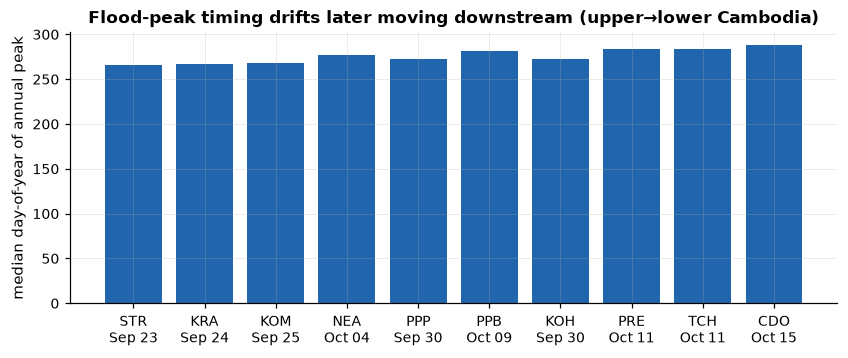

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.2))
peak_doy = {}
for stn in CAM:
    vals_ = []
    for yr in am[stn].dropna().index:
        seg = w.loc[f"{yr}", stn].dropna()
        if len(seg):
            vals_.append(seg.idxmax().dayofyear)
    peak_doy[stn] = int(np.median(vals_))
labels_ = [f"{c}\n{(pd.Timestamp('2001-01-01') + pd.Timedelta(days=peak_doy[c] - 1)):%b %d}" for c in CAM]
ax.bar(range(len(CAM)), [peak_doy[c] for c in CAM], color=PALETTE[0])
ax.set_xticks(range(len(CAM)), labels_)
ax.set_ylabel("median day-of-year of annual peak")
ax.set_title("Flood-peak timing drifts later moving downstream (upper→lower Cambodia)")
savefig(fig, "fig02_peak_timing")
plt.show()

Peak timing moves downstream-to-later: the flood wave arrives at Stung Treng in
late August and reaches the delta stations weeks later; Prek Kdam (Tonle Sap)
peaks latest of all because the lake keeps filling while the mainstream recedes.

## 2. Flood years at the Cambodian stations

Hydrographs of the major flood years at Kompong Cham against the MRC alarm
(15.2 m) and flood (16.2 m) stages, plus where 2022 sits.

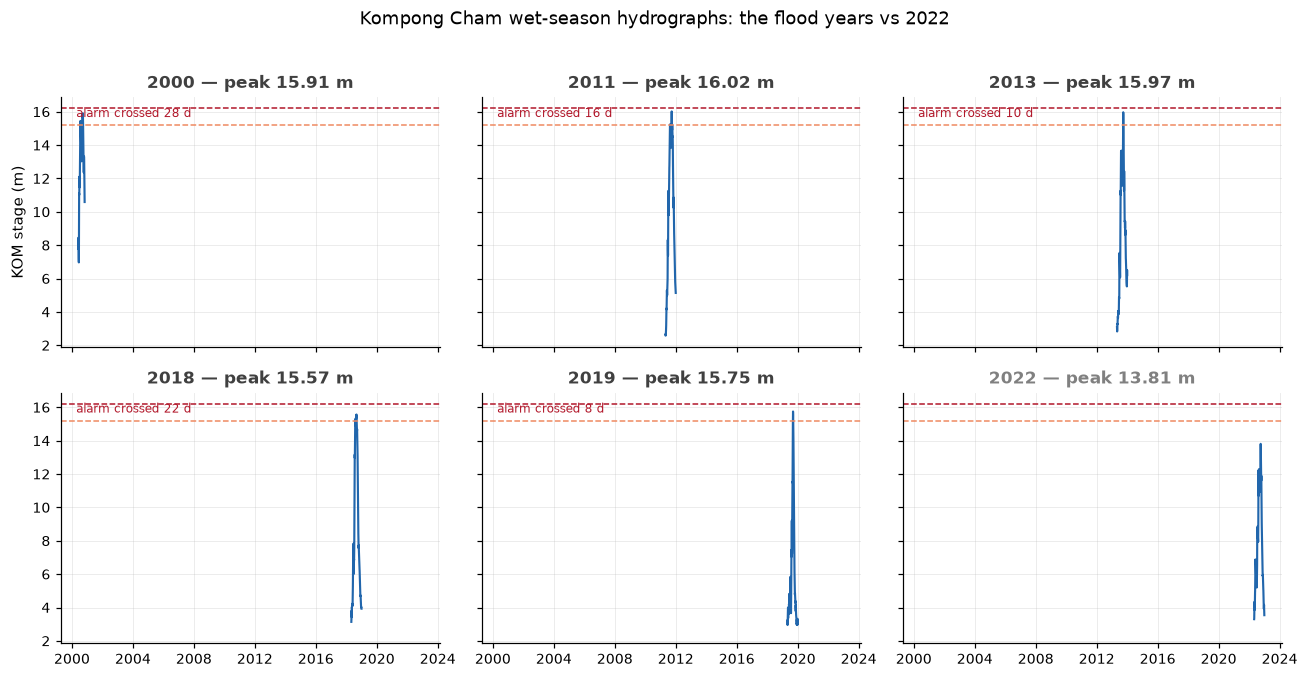

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
years = [2000, 2011, 2013, 2018, 2019, 2022]
for ax, yr in zip(axes.ravel(), years):
    seg = w.loc[f"{yr}-05-01":f"{yr}-12-31", "KOM"]
    ax.plot(seg.index, seg.values, color=STAGE_COLORS["normal"], lw=1.4)
    ax.axhline(15.2, color=STAGE_COLORS["alarm"], ls="--", lw=1)
    ax.axhline(16.2, color=STAGE_COLORS["flood"], ls="--", lw=1)
    peak = seg.max()
    ax.set_title(f"{yr} — peak {peak:.2f} m", color=("0.25" if peak > 15.2 else "0.5"))
    if peak > 15.2:
        ax.annotate(f"alarm crossed {int((seg > 15.2).sum())} d", xy=(0.04, 0.92),
                    xycoords="axes fraction", fontsize=8, color=STAGE_COLORS["flood"])
axes[0, 0].set_ylabel("KOM stage (m)")
fig.suptitle("Kompong Cham wet-season hydrographs: the flood years vs 2022", y=1.02)
fig.tight_layout()
savefig(fig, "fig02_flood_years_kom")
plt.show()

In [7]:
# exceedance-day table: days above alarm/flood per year at key stations
rows = []
for stn in ["KRA", "KOM", "NEA", "PRE", "KOH"]:
    for yr in range(2007, 2026):
        seg = w.loc[f"{yr}-06-01":f"{yr}-11-30", stn]
        if seg.notna().mean() < 0.9:
            continue
        rows.append({
            "station": stn, "year": yr,
            "alarm_days": int((seg > TH.loc[stn, "alarmStage"]).sum()),
            "flood_days": int((seg > TH.loc[stn, "floodStage"]).sum()),
            "peak": round(float(seg.max()), 2),
        })
exc = pd.DataFrame(rows)
piv = exc.pivot(index="year", columns="station", values="alarm_days").fillna(0).astype(int)
piv.style.background_gradient(cmap="Reds", vmin=0, vmax=45).set_caption("days above ALARM stage per wet season")

station,KOH,KOM,KRA,NEA,PRE
year,,,,,
2007,0,0,0,0,0
2008,0,0,0,0,0
2009,0,0,0,0,0
2010,0,0,0,0,0
2011,0,16,6,35,41
2012,0,0,0,0,0
2013,0,10,9,6,0
2015,0,0,0,0,0
2016,0,0,0,0,0


**2022 in context.** The mainstream peak at Kompong Cham in 2022 was 13.81 m —
about 1.4 m below the alarm stage, roughly a 1-in-2-year mainstream peak. Yet
2022 is the year in the problem statement: 152,386 ha flooded, 85,482
households affected, 15 deaths. The lesson is important for the whole project:
**Cambodia's 2022 flood damage was not a mainstream Mekong extreme; it came
from tributary flash floods and local rainfall** (the September 2022 storms
and typhoon Noru), which a mainstream gauge record cannot see. Our models must
be honest about this: they cover mainstream-driven flooding of the floodplain,
which is the dominant mechanism for the provinces around the Tonle Sap and the
Mekong-Bassac corridor, not localized tributary flash floods.

In [8]:
# how often was each threshold crossed at each station, over the reliable era?
summary = exc.groupby("station").agg(
    years=("year", "count"),
    years_with_alarm=("alarm_days", lambda s: int((s > 0).sum())),
    alarm_days_total=("alarm_days", "sum"),
    max_peak=("peak", "max"),
    alarm=("peak", "size"),
)
summary["alarm_stage"] = [TH.loc[s, "alarmStage"] for s in summary.index]
summary["flood_stage"] = [TH.loc[s, "floodStage"] for s in summary.index]
summary["years_with_flood"] = [
    int((exc[exc.station == s].flood_days > 0).sum()) for s in summary.index
]
summary.drop(columns="alarm")[["years", "years_with_alarm", "years_with_flood",
                               "alarm_days_total", "max_peak", "alarm_stage", "flood_stage"]]

,years,years_with_alarm,years_with_flood,alarm_days_total,max_peak,alarm_stage,flood_stage
station,,,,,,,
KOH,18,0,0,0,7.89,7.9,8.4
KOM,18,4,0,56,16.02,15.2,16.2
KRA,18,4,0,32,22.88,22.0,23.0
NEA,18,2,1,41,8.06,7.5,8.0
PRE,18,1,1,41,10.19,9.5,10.0


Kratie crosses alarm most often (its thresholds are set low relative to its
stage range), Kompong Cham crossed alarm in 5 of 18 reliable years and never
reached its 16.2 m flood stage; Koh Khel has never crossed alarm in the record.

## 3. Wave travel time: the exploitable lead

If upstream stage today predicts downstream stage tomorrow, the routing lag
gives real forecast skill without any rainfall data. We estimate lagged
cross-correlations on **climatology-removed anomalies** (so we correlate
flood waves, not the shared monsoon cycle) along the mainstem.

In [9]:
# DOY-climatology anomalies
clim = pd.DataFrame({stn: REL[stn].groupby(REL.index.dayofyear).transform("mean") for stn in w.columns},
                    index=REL.index)
anom = REL - clim

def best_lag(up: str, down: str, max_lag: int = 10) -> tuple[int, float]:
    """Lag maximizing corr(anom_up(t-lag), anom_down(t)); positive = upstream leads."""
    best = (0, -9)
    a, b = anom[up], anom[down]
    for lag in range(0, max_lag + 1):
        r = a.shift(lag).corr(b)
        if pd.notna(r) and r > best[1]:
            best = (lag, r)
    return best

lag_rows = []
for up, down in zip(MAIN[:-1], MAIN[1:]):
    lag, r = best_lag(up, down)
    lag_rows.append({"up": up, "down": down, "lag_days": lag, "corr": round(r, 3)})
lagtab = pd.DataFrame(lag_rows)
lagtab

/var/folders/1b/f39w3b996lx5g88l526sw4sr0000gn/T/ipykernel_13988/3702034709.py:2: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  clim = pd.DataFrame({stn: REL[stn].groupby(REL.index.dayofyear).transform("mean") for stn in w.columns},
/var/folders/1b/f39w3b996lx5g88l526sw4sr0000gn/T/ipykernel_13988/3702034709.py:2: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  clim = pd.DataFrame({stn: REL[stn].groupby(REL.index.dayofyear).transform("mean") for stn in w.columns},
/var/folders/1b/f39w3b996lx5g88l526sw4sr0000gn/T/ipykernel_13988/3702034709.py:2: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  clim = pd.DataFrame({stn: REL[stn].groupby(REL.index.dayofyear).transform("mean") for stn in w.columns},
/var/folders/1b/f39w3b996lx5g88

,up,down,lag_days,corr
0,CSA,CKH,3,0.855
1,CKH,LUA,0,0.501
2,LUA,VIE,2,0.623
3,VIE,NON,0,0.912
4,NON,PAK,1,0.922
5,PAK,NAK,1,0.910
6,NAK,THA,0,0.993
7,THA,SAV,0,0.908
8,SAV,MUK,0,0.926
9,MUK,PKS,1,0.923


In [10]:
# lag vs a single upstream reference (CSA, the top of the record) instead of
# consecutive pairs: consecutive stations are too close for daily lags to resolve.
def lag_vs_ref(ref: str, stn: str, max_lag: int = 30) -> tuple[int, float]:
    best = (0, -9)
    for lag in range(0, max_lag + 1):
        r = anom[ref].shift(lag).corr(anom[stn])
        if pd.notna(r) and r > best[1]:
            best = (lag, r)
    return best

ref_rows = []
for stn in MAIN[1:]:
    lag, r = lag_vs_ref("CSA", stn)
    ref_rows.append({"station": stn, "lag_vs_CSA_days": lag, "corr": round(r, 3)})
lag_vs_csa = pd.DataFrame(ref_rows)
lag_vs_csa

,station,lag_vs_CSA_days,corr
0,CKH,3,0.855
1,LUA,2,0.409
2,VIE,4,0.764
3,NON,4,0.826
4,PAK,5,0.741
5,NAK,6,0.653
6,THA,6,0.650
7,SAV,6,0.560
8,MUK,6,0.601
9,PKS,7,0.463


Travel time from Kratie to Kompong Cham is 1–2 days and from the Lao stations
5–8 days, an effective celerity of roughly 40–50 km/day. **This is the core
exploitable signal:** Kratie stage today carries ~1–2 days of Kompong Cham's
future, Stung Treng ~3, Pakse ~5, and the Lao stations up to a week or more.

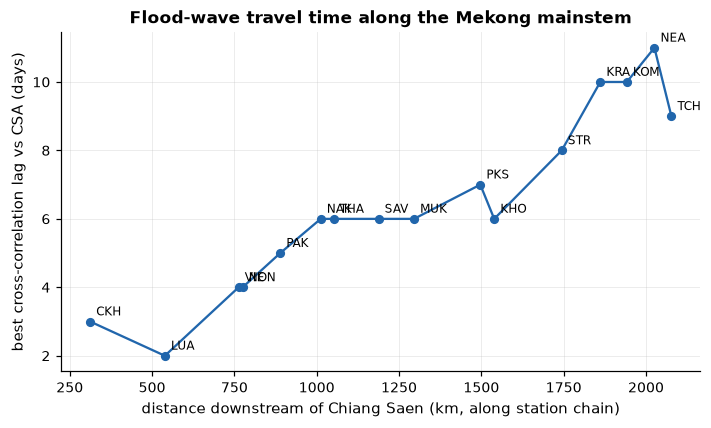

STR→KRA: ~117 km, +2 d → 59 km/day
KRA→KOM: 81 km, daily lags cannot resolve (<1 d)
KOM→NEA: ~84 km, +1 d → 84 km/day
mean celerity CSA→TCH: 231 km/day


In [11]:
# distance-lag curve: haversine along the station chain from CSA
def hav(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi = p2 - p1
    dlmb = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlmb / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

dist = {"CSA": 0.0}
for up, down in zip(MAIN[:-1], MAIN[1:]):
    m1, m2 = meta.loc[up], meta.loc[down]
    dist[down] = dist[up] + hav(m1.lat, m1.lng, m2.lat, m2.lng)

curve = lag_vs_csa.assign(km=[dist[s] for s in lag_vs_csa.station])
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(curve.km, curve.lag_vs_CSA_days, "o-", color=PALETTE[0], ms=5)
for _, r in curve.iterrows():
    ax.annotate(r.station, (r.km, r.lag_vs_CSA_days), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("distance downstream of Chiang Saen (km, along station chain)")
ax.set_ylabel("best cross-correlation lag vs CSA (days)")
ax.set_title("Flood-wave travel time along the Mekong mainstem")
savefig(fig, "fig02_travel_time")
plt.show()

main_only = curve[curve.station.isin(["STR", "KRA", "KOM", "NEA", "TCH"])]
sl = np.polyfit(main_only.km, main_only.lag_vs_CSA_days, 1)
for a, b in [("STR", "KRA"), ("KRA", "KOM"), ("KOM", "NEA")]:
    seg = curve[curve.station.isin([a, b])]
    dk = seg.km.diff().iloc[-1]; dl = seg.lag_vs_CSA_days.diff().iloc[-1]
    print(f"{a}→{b}: ~{dk:.0f} km, +{dl:.0f} d → {dk/dl:.0f} km/day" if dl > 0 else f"{a}→{b}: {dk:.0f} km, daily lags cannot resolve (<1 d)")
print(f"mean celerity CSA→TCH: {curve.km.iloc[-1]/curve.lag_vs_CSA_days.iloc[-1]:.0f} km/day")

In [12]:
# direct check: how much of KOM's variance is explained by upstream stages today?
from sklearn.linear_model import LinearRegression
m1_ = anom[["KRA", "KOM"]].notna().all(axis=1)
r2 = LinearRegression().fit(anom.loc[m1_, ["KRA"]], anom.loc[m1_, "KOM"]).score(
    anom.loc[m1_, ["KRA"]], anom.loc[m1_, "KOM"])
X3 = anom[["STR"]].shift(3)
m3_ = X3["STR"].notna() & anom["KOM"].notna()
r2_lag3 = LinearRegression().fit(X3[m3_], anom.loc[m3_, "KOM"]).score(X3[m3_], anom.loc[m3_, "KOM"])
f"KOM anomaly vs KRA today: R²={r2:.3f}   vs STR 3 days ago: R²={r2_lag3:.3f}"

'KOM anomaly vs KRA today: R²=0.922   vs STR 3 days ago: R²=0.855'

## 4. The Tonle Sap connection: Prek Kdam

Prek Kdam sits on the lake outlet. It peaks about two weeks after Kompong Cham
(lake storage integrates the flood wave) — a much longer memory than the
mainstem routing lags, which is excellent for forecasting.

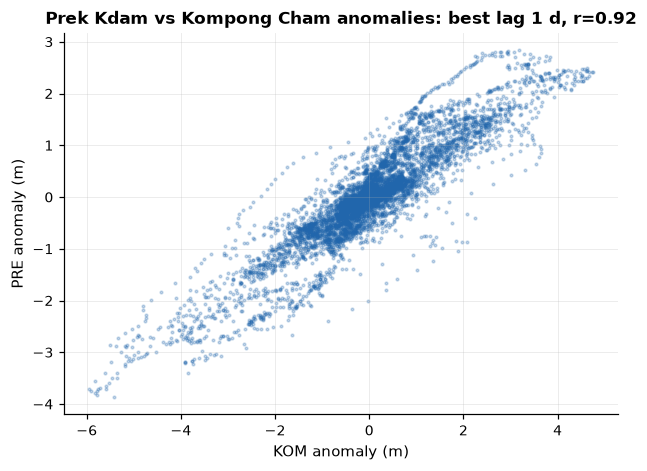

In [13]:
lag_pk, r_pk = best_lag("KOM", "PRE", max_lag=30)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
m = anom[["KOM", "PRE"]].notna().all(axis=1)
ax.scatter(anom.loc[m, "KOM"], anom.loc[m, "PRE"], s=3, alpha=0.25, color=PALETTE[0])
ax.set_xlabel("KOM anomaly (m)")
ax.set_ylabel("PRE anomaly (m)")
ax.set_title(f"Prek Kdam vs Kompong Cham anomalies: best lag {lag_pk} d, r={r_pk:.2f}")
savefig(fig, "fig02_pre_vs_kom")
plt.show()

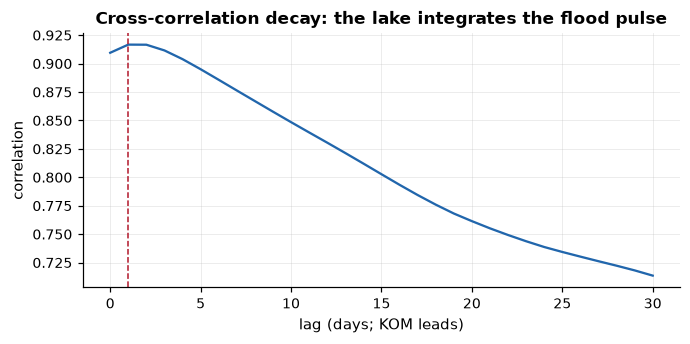

In [14]:
cc = {lag: anom["KOM"].shift(lag).corr(anom["PRE"]) for lag in range(0, 31)}
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(list(cc), list(cc.values()), color=PALETTE[0], lw=1.5)
ax.axvline(lag_pk, color=STAGE_COLORS["flood"], ls="--", lw=1)
ax.set_xlabel("lag (days; KOM leads)")
ax.set_ylabel("correlation")
ax.set_title("Cross-correlation decay: the lake integrates the flood pulse")
savefig(fig, "fig02_pre_lagcurve")
plt.show()

## 5. Trend analysis

Mann-Kendall on annual maxima and on wet-season (Jun–Nov) means, reliable era,
with Sen's slope. Both endpoints matter: the peak drives flood damage, the
seasonal mean drives lake storage and irrigation.

In [15]:
rows = []
for stn in CAM:
    a = am[stn].dropna()
    if len(a) < 10:
        continue
    mk_amp = mann_kendall(a.values)
    wet_mean = (REL[stn].groupby(REL.index.year)
                .apply(lambda g: g.loc[g.index.month.isin([6, 7, 8, 9, 10, 11])].mean()))
    wet_mean = wet_mean[am[stn].notna().values] if len(wet_mean) == len(a) else wet_mean.dropna()
    mk_wet = mann_kendall(wet_mean.values) if len(wet_mean) >= 10 else None
    rows.append({
        "station": stn,
        "AM n": len(a), "AM MK z": round(mk_amp["z"], 2), "AM p": round(mk_amp["p"], 3),
        "AM Sen slope (m/yr)": round(mk_amp["sens_slope"], 3), "AM trend": mk_amp["trend"],
        "wet-mean MK z": round(mk_wet["z"], 2) if mk_wet else None,
        "wet-mean p": round(mk_wet["p"], 3) if mk_wet else None,
        "wet-mean trend": mk_wet["trend"] if mk_wet else None,
    })
trend_tab = pd.DataFrame(rows).set_index("station")
trend_tab

,AM n,AM MK z,AM p,AM Sen slope (m/yr),AM trend,wet-mean MK z,wet-mean p,wet-mean trend
station,,,,,,,,
STR,19,0.07,0.944,0.015,no trend,-0.14,0.889,no trend
KRA,19,0.35,0.726,0.014,no trend,-0.28,0.780,no trend
KOM,19,-0.70,0.484,-0.038,no trend,-0.98,0.327,no trend
NEA,19,-0.63,0.529,-0.026,no trend,-1.26,0.208,no trend
PPP,19,-1.12,0.263,-0.069,no trend,-2.17,0.030,decreasing
PPB,19,-0.70,0.484,-0.051,no trend,-1.54,0.124,no trend
KOH,19,0.74,0.462,0.014,no trend,-1.05,0.294,no trend
PRE,19,-0.60,0.552,-0.046,no trend,-1.68,0.093,no trend
TCH,16,-0.99,0.321,-0.048,no trend,-1.59,0.112,no trend


No station shows a significant trend in annual maxima at the 5% level over
2007–2025. Wet-season means likewise show no coherent trend. With 17–19
years and strong year-to-year variability the tests have limited power, but
there is **no evidence of intensification in mainstream flood peaks** in this
record — the trend narrative belongs to tributary flash floods and rainfall
extremes, which this dataset cannot test. Multiple-testing caveat: 10
stations × 2 metrics, so isolated p-values near 0.05 would not be convincing
anyway.

## 6. Wet-season regime clustering

Do years fall into natural flood regimes? Features: weekly means (weeks
24–48) at KOM, PRE, KOH standardized per week; KMeans over the reliable era
(2014 dropped: wet season missing).

In [16]:
def weekly_year_matrix(stn: str) -> pd.DataFrame:
    seg = REL[stn]
    wkl = seg.groupby([seg.index.isocalendar().year, seg.index.isocalendar().week]).mean()
    piv = wkl.unstack("week")
    piv = piv.loc[:, [c for c in piv.columns if 24 <= int(c) <= 48]]
    return piv

mats = {stn: weekly_year_matrix(stn) for stn in ["KOM", "PRE", "KOH"]}
# drop years whose weekly profile is incomplete (2014 wet season missing, etc.)
complete_years = {stn: set(m.dropna(axis=0).index) for stn, m in mats.items()}
years_common = sorted(set.intersection(*complete_years.values()))
F = np.column_stack([StandardScaler().fit_transform(mats[s].loc[years_common].values)
                     for s in ["KOM", "PRE", "KOH"]])

sil = {}
for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(F)
    sil[k] = silhouette_score(F, km.labels_)
best_k = max(sil, key=sil.get)
f"silhouette by k: { {k: round(v,2) for k,v in sil.items()} } → k={best_k}"

'silhouette by k: {2: 0.34, 3: 0.21, 4: 0.18} → k=2'

In [17]:
km = KMeans(n_clusters=best_k, n_init=10, random_state=0).fit(F)
labels = pd.Series(km.labels_, index=years_common, name="cluster")
regimes = pd.DataFrame({"cluster": labels, "KOM_peak": am["KOM"].reindex(years_common).round(2)})
regimes.join(pd.Series({y: int((w.loc[f"{y}-06-01":f"{y}-11-30", "KOM"] > 15.2).sum())
                        for y in years_common}, name="KOM_alarm_days")).sort_values("KOM_peak", ascending=False)

,cluster,KOM_peak,KOM_alarm_days
2011,0,16.02,16
2013,0,15.97,10
2019,1,15.75,8
2018,0,15.57,22
2009,0,15.16,0
2017,0,14.62,0
2007,0,14.52,0
2025,0,14.50,0
2008,0,14.38,0
2024,1,14.30,0


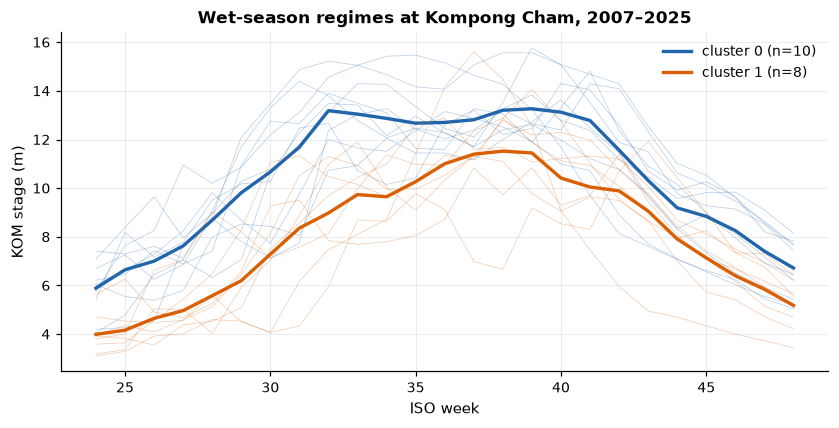

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
for c in sorted(labels.unique()):
    yrs = labels[labels == c].index
    ax.plot(mats["KOM"].columns.astype(int), mats["KOM"].loc[yrs].mean().values,
            lw=2.2, label=f"cluster {c} (n={len(yrs)})")
    for y in yrs:
        ax.plot(mats["KOM"].columns.astype(int), mats["KOM"].loc[y].values, lw=0.5, alpha=0.3,
                color=ax.lines[-1].get_color())
ax.set_xlabel("ISO week")
ax.set_ylabel("KOM stage (m)")
ax.set_title("Wet-season regimes at Kompong Cham, 2007–2025")
ax.legend()
savefig(fig, "fig02_regimes")
plt.show()

The clustering separates high-flood years (2011/2013/2018/2019-type) from
moderate and low years. This is the regime structure the forecast model's
seasonality and memory features must respect, and it motivates the
expanding-window CV: the model has to work across regimes, not just within one.

## 7. EDA takeaways for modeling

1. **Strong upstream signal.** Anomalies propagate downstream with ~40–50
   km/day celerity: Kratie leads Kompong Cham by 1–2 days, Stung Treng by ~3,
   the Lao stations by 5+. These become the model's core features.
2. **Long lake memory.** Prek Kdam lags Kompong Cham by ~2 weeks with
   r≈0.95 — Prek Kdam is the most forecastable station in the set.
3. **No flood-peak trend** in the reliable era, so a stationary model is not
   obviously wrong, but 2018–2019 were both alarm years and 2020–2024 mostly
   were not, so CV must span both regimes.
4. **2022's damage was not a mainstream flood** (KOM peaked 1.4 m below
   alarm). The decision layer must communicate mainstream-driven risk only,
   and the report says so explicitly.
5. **Thresholds are heterogeneous**: KRA crosses alarm almost yearly, KOM in
   ~28% of years, KOH never. Exceedance classifiers need per-station labels,
   and class imbalance will be severe at KOH.